# Exercice 3 : Streaming de données météo en direct

## 3.1 Écrivez un producteur 
current_weathe 
 qui interroge lʼAPI Open-Meteo toutes les 30 second s
pour chacune des villes suivantes :

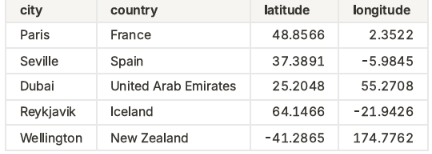


In [1]:
import requests
import json
import time
from datetime import datetime
from kafka import KafkaProducer

TOPIC = "weather_stream"

villes = [
    {"city": "Paris",      "country": "France",               "latitude": 48.8566,  "longitude": 2.3522},
    {"city": "Seville",    "country": "Spain",                "latitude": 37.3891,  "longitude": -5.9845},
    {"city": "Dubai",      "country": "United Arab Emirates", "latitude": 25.2048,  "longitude": 55.2708},
    {"city": "Reykjavik",  "country": "Iceland",              "latitude": 64.1466,  "longitude": -21.9426},
    {"city": "Wellington", "country": "New Zealand",          "latitude": -41.2865, "longitude": 174.7762},
]

URL = "https://api.open-meteo.com/v1/forecast?latitude={latitude}&longitude={longitude}&current=temperature_2m,wind_speed_10m,weather_code&wind_speed_unit=ms"


In [2]:
def get_weather(ville):
    url = URL.format(latitude=ville["latitude"], longitude=ville["longitude"])
    reponse = requests.get(url, timeout=10)
    donnees = reponse.json()
    donnees["city"] = ville["city"]
    donnees["country"] = ville["country"]
    return donnees

# test sur Paris
test = get_weather(villes[0])
print(json.dumps(test, indent=2))


{
  "latitude": 48.853382,
  "longitude": 2.355208,
  "generationtime_ms": 0.28204917907714844,
  "utc_offset_seconds": 0,
  "timezone": "GMT",
  "timezone_abbreviation": "GMT",
  "elevation": 36.0,
  "current_units": {
    "time": "iso8601",
    "interval": "seconds",
    "temperature_2m": "\u00b0C",
    "wind_speed_10m": "m/s",
    "weather_code": "wmo code"
  },
  "current": {
    "time": "2026-11-10T14:45",
    "interval": 900,
    "temperature_2m": 12.4,
    "wind_speed_10m": 2.13,
    "weather_code": 3
  },
  "city": "Paris",
  "country": "France"
}


## Boucle d'envoi.



In [ ]:
producer = KafkaProducer(
    bootstrap_servers="kafka:9092",
    value_serializer=lambda v: json.dumps(v).encode("utf-8")
)

print("Producteur current_weather démarré, envoi toutes les 30 s dans", TOPIC)

try:
    while True:
        heure = datetime.now().strftime("%H:%M:%S")
        for ville in villes:
            try:
                meteo = get_weather(ville)
                producer.send(TOPIC, meteo)
                print(heure, "|", ville["city"], "|",
                      meteo["current"]["temperature_2m"], "°C |",
                      meteo["current"]["wind_speed_10m"], "m/s | code", meteo["current"]["weather_code"])
            except Exception as e:
                print(heure, "| erreur pour", ville["city"], ":", e)
        producer.flush()
        time.sleep(30)
except KeyboardInterrupt:
    print("Producteur arrêté.")
    producer.close()


Producteur current_weather démarré, envoi toutes les 30 s dans weather_stream
14:51:48 | Paris | 12.4 °C | 2.13 m/s | code 3
14:51:48 | Seville | 21.3 °C | 5.42 m/s | code 80
14:51:48 | Dubai | 30.2 °C | 3.0 m/s | code 0
14:51:48 | Reykjavik | 6.8 °C | 6.8 m/s | code 0
14:51:48 | Wellington | 15.4 °C | 8.54 m/s | code 51
14:52:18 | Paris | 12.4 °C | 2.13 m/s | code 3
14:52:18 | Seville | 21.3 °C | 5.42 m/s | code 80
14:52:18 | Dubai | 30.2 °C | 3.0 m/s | code 0
14:52:18 | Reykjavik | 6.8 °C | 6.8 m/s | code 0
14:52:18 | Wellington | 15.4 °C | 8.54 m/s | code 51
14:52:50 | Paris | 12.4 °C | 2.13 m/s | code 3
14:52:50 | Seville | 21.3 °C | 5.42 m/s | code 80
14:52:50 | Dubai | 30.2 °C | 3.0 m/s | code 0
14:52:50 | Reykjavik | 6.8 °C | 6.8 m/s | code 0
14:52:50 | Wellington | 15.4 °C | 8.54 m/s | code 51
14:53:20 | Paris | 12.4 °C | 2.13 m/s | code 3
14:53:20 | Seville | 21.3 °C | 5.42 m/s | code 80
14:53:20 | Dubai | 30.2 °C | 3.0 m/s | code 0
14:53:20 | Reykjavik | 6.8 °C | 6.8 m/s | co